In [ ]:
import pandas as pd
import sklearn as skl
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import numpy as np

ModuleNotFoundError: No module named 'statsmodels'

In [8]:
imgs = pd.read_csv(r'C:\Users\Jaxon\OneDrive\Computer_Files_Surface\School_Files\UT_Files\Fall_2026_Files\SDS 336\Project\imgs.csv')
print(imgs.head(1))

                  image                                               path  \
0  1_2020-04-03_L_3.jpg  C:\Users\Jaxon\OneDrive\Computer_Files_Surface...   

   patient_id gender  gestational_age  birth_weight  plurality delivery_mode  \
0           1   male               34          2650          1     vaginally   

    label     avg_R     avg_G     avg_B  brightness_prop  
0  normal  0.478479  0.467667  0.441962         0.074147  


In [9]:
imgs.loc[imgs['label'] == 'normal', 'label_numeric'] = 0
imgs.loc[imgs['label'] == 'Stage 1 ROP', 'label_numeric'] = 1
imgs.loc[imgs['label'] == 'Stage 1 ROP', 'label_numeric'] = 2
imgs.loc[imgs['label'] == 'Stage 1 ROP', 'label_numeric'] = 3
imgs.loc[imgs['label'] == 'Stage 1 ROP', 'label_numeric'] = 4
imgs.loc[imgs['label'] == 'Stage 1 ROP', 'label_numeric'] = 5

In [10]:
imgs_numeric = imgs.drop(columns=['image','path','patient_id','gender','delivery_mode','label'])

In [11]:
imgs_numeric_features = imgs_numeric.drop(columns=['label_numeric'])
imgs_numeric_label = imgs_numeric[['label_numeric']]
print(imgs_numeric_features.head(1))
print(imgs_numeric_label.head(1))

   gestational_age  birth_weight  plurality     avg_R     avg_G     avg_B  \
0               34          2650          1  0.478479  0.467667  0.441962   

   brightness_prop  
0         0.074147  
   label_numeric
0            0.0


In [12]:
imgs_numeric_features_engineered = imgs_numeric_features.copy()
feature_columns = [col for col in imgs_numeric_features.columns if col != 'label_numeric']

scaler = StandardScaler()
scaler.fit(imgs_numeric_features)
imgs_numeric_features_engineered[feature_columns] = scaler.transform(imgs_numeric_features[feature_columns])

print(imgs_numeric_features_engineered.head())

   gestational_age  birth_weight  plurality     avg_R     avg_G     avg_B  \
0         0.903152      1.497440   -0.61096 -0.417329  0.122384  0.290371   
1         0.903152      1.497440   -0.61096 -0.301605  0.315305  0.518057   
2         1.654167     -1.316465   -0.61096  1.316303  1.449814 -0.020203   
3         1.654167     -1.316465   -0.61096  1.329120  1.843772  0.206623   
4        -0.849215     -0.779860    1.52880  0.564966  0.417268  0.970107   

   brightness_prop  
0         0.497023  
1         2.135617  
2        -0.437999  
3        -0.627486  
4         1.216153  


<Axes: >

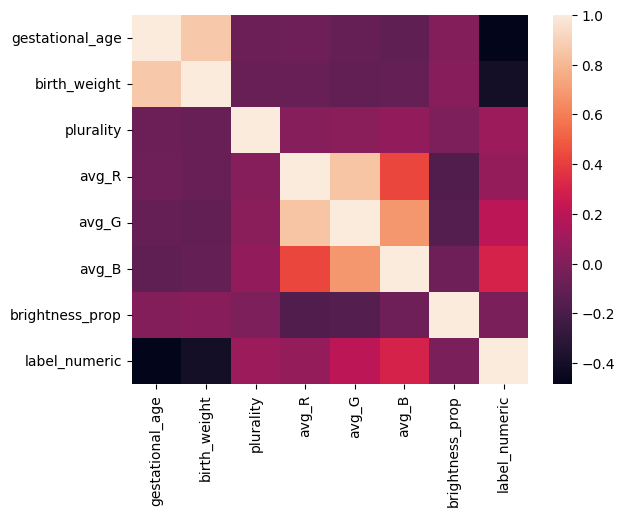

In [13]:
sns.heatmap(imgs_numeric.corr())

In [34]:
X = imgs_numeric_features_engineered.copy()
X['intercept'] = 1

# 3. Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# 4. Filter out the intercept row from final display
vif_data = vif_data[vif_data["feature"] != "intercept"]
print(vif_data)

            feature        VIF
0   gestational_age   4.029780
1      birth_weight   4.014696
2         plurality   1.017926
3             avg_R   4.971480
4             avg_G   7.608581
5             avg_B   2.313252
6              g_sd   2.999392
7          fov_frac   1.157842
8           hi_prop   1.228342
9         edge_mean  14.476422
10         edge_p95  10.267888
